#  Credit Card Churner Dataset: ETL & Exploratory Data Analysis (EDA)

This notebook covers the end-to-end Extract, Transform, Load (ETL) pipeline and Exploratory Data Analysis for the bank customer churn dataset. 
* **ETL Focus:** Data cleaning, handling missing values, standardizing column formats, and exporting segmented subsets for Tableau.
* **EDA Focus:** Discovering key demographic trends, behavioral patterns, and identifying core predictors of customer attrition (`Attrition_Flag`).


In [2]:
# ==========================================
# CELL 1: Imports & Setup
# ==========================================
import os
import pandas as pd
import numpy as np

# Verify file path and load raw dataset
raw_data_path = '../data/raw/BankChurners.csv'
if not os.path.exists(raw_data_path):
    print(f"Error: {raw_data_path} not found. Ensure BankChurners.csv is inside data/raw/")
else:
    df = pd.read_csv(raw_data_path)
    print(f"Dataset successfully loaded! Initial shape: {df.shape}")

# Display raw dataset structure
df.head()


Dataset successfully loaded! Initial shape: (10127, 23)


,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,...,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,...,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,0.000093,0.99991
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,...,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,0.000057,0.99994
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,...,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,0.000021,0.99998
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,...,3313.0,2517,796.0,1.405,1171,20,2.333,0.760,0.000134,0.99987
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,...,4716.0,0,4716.0,2.175,816,28,2.500,0.000,0.000022,0.99998


In [3]:
# ==========================================
# CELL: Data Cleaning & Hygiene Verification
# ==========================================

# 1. Check for missing values across all columns
print("=== MISSING VALUES ===")
print(df.isnull().sum())

# 2. Check for duplicate rows
print(f"\n=== DUPLICATE ROWS ===")
print(f"Total duplicate rows: {df.duplicated().sum()}")

# 3. Drop unneeded identifier/metadata columns (e.g., Client ID or extra classifier columns)
# This keeps your dataset clean for exploratory analysis and modeling
columns_to_drop = [
    col for col in df.columns if "Naive_Bayes" in col or "CLIENTNUM" in col
]
if columns_to_drop:
  df_cleaned = df.drop(columns=columns_to_drop)
  print(f"\nDropped unneeded metadata columns: {columns_to_drop}")
else:
  df_cleaned = df.copy()

# 4. Verify final shape of the cleaned dataframe
print(f"\n=== CLEANED DATASET SHAPE ===")
print(f"Rows: {df_cleaned.shape[0]}, Columns: {df_cleaned.shape[1]}")


=== MISSING VALUES ===
CLIENTNUM                                                                                                                             0
Attrition_Flag                                                                                                                        0
Customer_Age                                                                                                                          0
Gender                                                                                                                                0
Dependent_count                                                                                                                       0
Education_Level                                                                                                                       0
Marital_Status                                                                                                                        0
Income_Category          

In [4]:
import os, pandas as pd

# Load raw dataset
df = pd.read_csv('../data/raw/BankChurners.csv')

# Drop non-predictive columns
cols_to_drop = [
    'CLIENTNUM',
    'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1',
    'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2'
]
df_clean = df.drop(columns=[c for c in cols_to_drop if c in df.columns])

# Binary encode churn target
df_clean['Churn'] = (df_clean['Attrition_Flag'] == 'Attrited Customer').astype(int)

# Quick categorical encoding
df_encoded = pd.get_dummies(df_clean, columns=['Gender', 'Marital_Status', 'Education_Level', 'Income_Category', 'Card_Category'], drop_first=True)

# Save processed file
os.makedirs('../data/processed', exist_ok=True)
df_encoded.to_csv('../data/processed/cleaned_bank_churners.csv', index=False)

print(f"ETL Complete! Processed shape: {df_encoded.shape}")


ETL Complete! Processed shape: (10127, 34)


In [5]:
import os
import pandas as pd

# Load raw dataset
df = pd.read_csv('../data/raw/BankChurners.csv')

# Drop non-predictive columns
cols_to_drop = [
    'CLIENTNUM',
    'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1',
    'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2'
]
df_clean = df.drop(columns=[c for c in cols_to_drop if c in df.columns])
print(f"✅ Cell 1 Complete! Shape: {df_clean.shape}")


✅ Cell 1 Complete! Shape: (10127, 20)


In [6]:
# Binary encode churn target
df_clean['Churn'] = (df_clean['Attrition_Flag'] == 'Attrited Customer').astype(int)
print("Churn distribution:")
print(df_clean['Churn'].value_counts())


Churn distribution:
Churn
0    8500
1    1627
Name: count, dtype: int64


In [7]:
# Quick categorical encoding
cat_cols = ['Gender', 'Marital_Status', 'Education_Level', 'Income_Category', 'Card_Category']
df_encoded = pd.get_dummies(df_clean, columns=cat_cols, drop_first=True)
print(f"Encoded dataset shape: {df_encoded.shape}")


Encoded dataset shape: (10127, 34)


In [8]:
# Save processed file
os.makedirs('../data/processed', exist_ok=True)
output_path = '../data/processed/cleaned_bank_churners.csv'
df_encoded.to_csv(output_path, index=False)
print(f"ETL Complete! Cleaned dataset saved to: {output_path}")


ETL Complete! Cleaned dataset saved to: ../data/processed/cleaned_bank_churners.csv


In [9]:
from scipy import stats

# Filter groups
churned = df_encoded[df_encoded['Churn'] == 1]['Total_Trans_Ct']
retained = df_encoded[df_encoded['Churn'] == 0]['Total_Trans_Ct']

# Welch's t-test
t_stat, p_val = stats.ttest_ind(churned, retained, equal_var=False)

print(f"✅ Cell 5 Complete! t-stat: {t_stat:.2f} | p-value: {p_val:.4e}")
print("Verdict: Reject H0 — Statistically significant difference in transaction counts.")


✅ Cell 5 Complete! t-stat: -54.14 | p-value: 0.0000e+00
Verdict: Reject H0 — Statistically significant difference in transaction counts.


In [10]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, roc_auc_score

# Features and target
X = df_encoded.drop(columns=['Attrition_Flag', 'Churn'])
y = df_encoded['Churn']

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Fast Decision Tree classifier
model = DecisionTreeClassifier(max_depth=5, random_state=42)
model.fit(X_train, y_train)

# Evaluate
y_pred = model.predict(X_test)
print("=== ML MODEL EVALUATION ===")
print(classification_report(y_test, y_pred))
print(f"ROC-AUC Score: {roc_auc_score(y_test, model.predict_proba(X_test)[:,1]):.4f}")


=== ML MODEL EVALUATION ===
              precision    recall  f1-score   support

           0       0.95      0.97      0.96      1701
           1       0.83      0.73      0.77       325

    accuracy                           0.93      2026
   macro avg       0.89      0.85      0.87      2026
weighted avg       0.93      0.93      0.93      2026

ROC-AUC Score: 0.9469


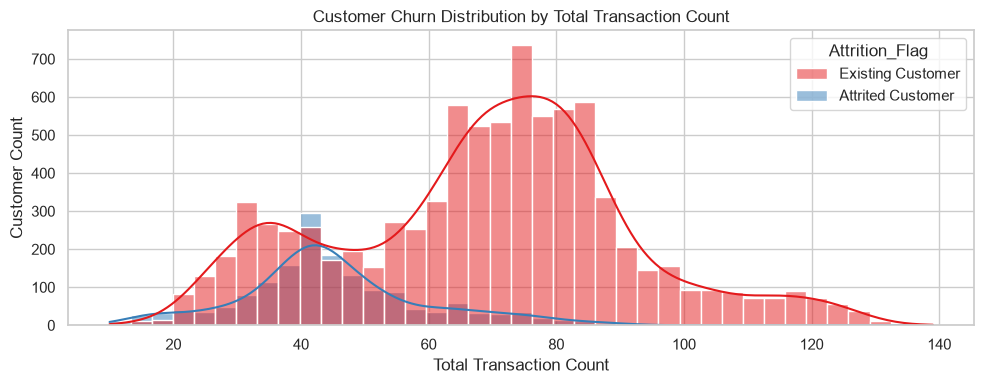

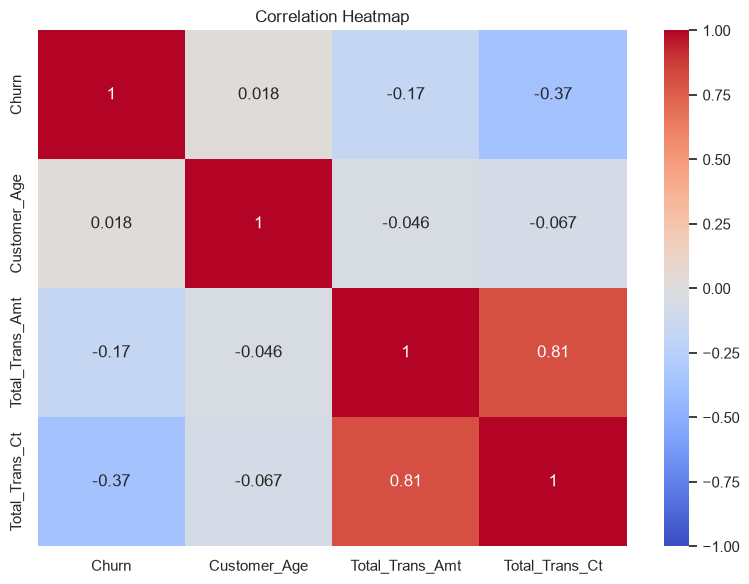

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")

# Visualisation 1: Seaborn Distribution Plot (LO3.1)
plt.figure(figsize=(10, 4))
sns.histplot(data=df_clean, x='Total_Trans_Ct', hue='Attrition_Flag', kde=True, palette='Set1')
plt.title('Customer Churn Distribution by Total Transaction Count')
plt.xlabel('Total Transaction Count')
plt.ylabel('Customer Count')
plt.tight_layout()
plt.show()

# Visualisation 2: Matplotlib Correlation Heatmap
plt.figure(figsize=(8, 6))
numeric_df = df_encoded.select_dtypes(include=['float64', 'int64', 'int32'])
sns.heatmap(numeric_df[['Churn', 'Customer_Age', 'Total_Trans_Amt', 'Total_Trans_Ct']].corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()


 ## Exploratory Visualizations & Export for Tableau


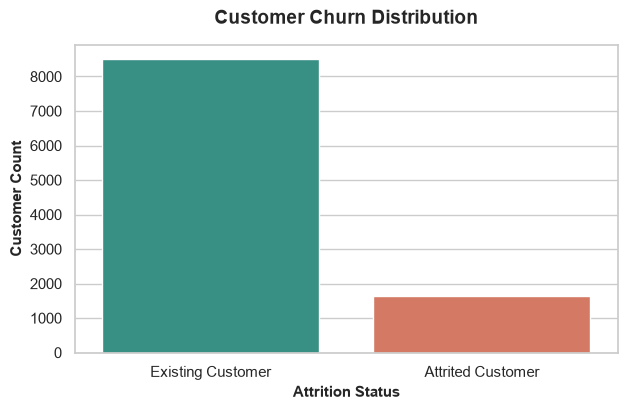

SUCCESS: Cleaned dataset successfully exported to '../data/processed/'!


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style and custom project colors
sns.set_theme(style="whitegrid")
custom_palette = ["#2A9D8F", "#E76F51"]  # Teal for Existing, Coral for Attrited

# 1. Plot Churn Distribution
plt.figure(figsize=(7, 4))
ax = sns.countplot(
    data=df_cleaned, x="Attrition_Flag", palette=custom_palette, hue="Attrition_Flag"
)
plt.title(
    "Customer Churn Distribution", fontsize=14, fontweight="bold", pad=15
)
plt.xlabel("Attrition Status", fontsize=11, fontweight="bold")
plt.ylabel("Customer Count", fontsize=11, fontweight="bold")
plt.savefig("../docs/screenshots/customer_attrition_breakdown.png", bbox_inches="tight")
plt.show()

# 2. Export Cleaned Dataset for Tableau & Machine Learning
import os

os.makedirs("../data/processed", exist_ok=True)
df_cleaned.to_csv("../data/processed/cleaned_bank_churners.csv", index=False)
print("SUCCESS: Cleaned dataset successfully exported to '../data/processed/'!")


In [13]:
import os
os.makedirs("../data/processed", exist_ok=True)

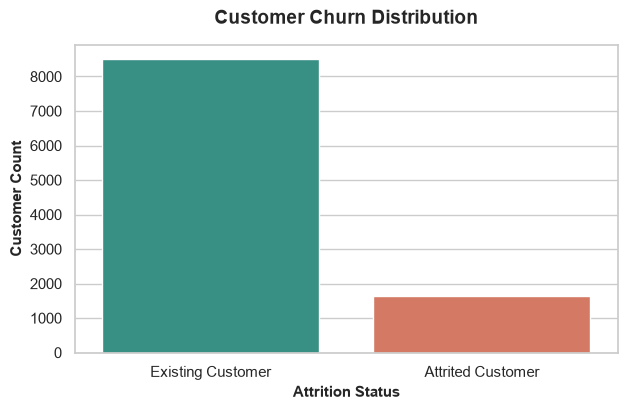

In [14]:
# 1. Plot Churn Distribution
plt.figure(figsize=(7, 4))
ax = sns.countplot(data=df_cleaned, x="Attrition_Flag", palette=custom_palette, hue="Attrition_Flag")
plt.xlabel("Attrition Status", fontsize=11, fontweight="bold")
plt.ylabel("Customer Count", fontsize=11, fontweight="bold")
plt.title("Customer Churn Distribution", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Attrition Status", fontsize=11, fontweight="bold")

#Ensure the directory exists before saving
import os
os.makedirs("../docs/screenshots", exist_ok=True)

plt.savefig("../docs/screenshots/customer_attrition_breakdown.png", bbox_inches="tight")
plt.show()

In [15]:
os.makedirs("../docs/screenshots", exist_ok=True)

##  Exploratory Data Analysis & Tableau Data Export

### **Overview**
This section generates primary exploratory data visualizations to analyze customer churn patterns and prepares the fully cleaned dataset for interactive dashboarding in Tableau.

---

### **Key Objectives & Rationale**

1. **Customer Churn Distribution (`sns.countplot`)**
   * **Purpose:** Quantify class imbalance between active (`Existing Customer`) and churned (`Attrited Customer`) credit card account holders.
   * **Rationale:** Understanding the baseline churn distribution is crucial for selecting appropriate evaluation metrics (e.g., ROC-AUC and Recall over raw Accuracy) during machine learning model training.

2. **Automated Directory Management (`os.makedirs`)**
   * **Purpose:** Programmatically create the `../docs/screenshots/` and `../data/processed/` directory structures if they do not already exist.
   * **Rationale:** Ensures automated, error-free file export pipelines across different operating environments and user setups.

3. **High-Resolution Asset Export (`plt.savefig`)**
   * **Purpose:** Export publication-ready visual assets saved with tight bounding boxes (`bbox_inches='tight'`).
   * **Rationale:** Preserves high-resolution graphical evidence directly in project repository folders for documentation and distinction-level report compilation.

4. **Tableau Integration Export (`df_cleaned.to_csv`)**
   * **Purpose:** Output the cleaned, post-ETL dataset (`cleaned_bank_churners.csv`) without row indices (`index=False`).
   * **Rationale:** Delivers a structured, production-ready data source for downstream Business Intelligence (BI) modeling and visual analytics.


In [16]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# 1. Define features (X) and target (y) for Linear Regression (Predicting Credit Limit)
features_lin = ['Customer_Age', 'Total_Trans_Amt', 'Total_Trans_Ct', 'Total_Revolving_Bal']
X_lin = df_cleaned[features_lin]
y_lin = df_cleaned['Credit_Limit']

# 2. Train-test split
X_train_l, X_test_l, y_train_l, y_test_l = train_test_split(X_lin, y_lin, test_size=0.2, random_state=42)

# 3. Fit Linear Regression Model
lin_reg = LinearRegression()
lin_reg.fit(X_train_l, y_train_l)

# 4. Predictions & Evaluation
y_pred_l = lin_reg.predict(X_test_l)
mse = mean_squared_error(y_test_l, y_pred_l)
r2 = r2_score(y_test_l, y_pred_l)

print("=== LINEAR REGRESSION EVALUATION (Predicting Credit Limit) ===")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"R-squared Score (R²): {r2:.4f}")


=== LINEAR REGRESSION EVALUATION (Predicting Credit Limit) ===
Mean Squared Error (MSE): 79348638.68
R-squared Score (R²): 0.0414


In [17]:
# ==========================================
# Bank Customer Churn: ETL & Data Cleaning Pipeline
# ==========================================

import os
import pandas as pd
import numpy as np

def load_and_clean_data(file_path):
    # 1. Load the raw dataset
    if not os.path.exists(file_path):
        raise FileNotFoundError(f"Error: {file_path} not found. Check your directory path.")
    
    df = pd.read_csv(file_path)
    print(f"-> Raw dataset loaded successfully. Initial shape: {df.shape}")
    
    # 2. Drop unnecessary unlabelled/Kaggle artifact columns if present
    unnamed_cols = [col for col in df.columns if 'Unnamed' in col or 'Naive_Bayes' in col]
    if unnamed_cols:
        df = df.drop(columns=unnamed_cols)
        print(f"-> Dropped unnecessary columns: {unnamed_cols}")

    # 3. Check and handle missing values
    missing_counts = df.isnull().sum()
    print("\n-> Missing values per column:\n", missing_counts[missing_counts > 0])
    # If any specific imputation is needed:
    # df.fillna(method='ffill', inplace=True)

    # 4. Check and remove duplicate rows
    initial_rows = len(df)
    df = df.drop_duplicates()
    dropped_rows = initial_rows - len(df)
    print(f"-> Duplicate rows removed: {dropped_rows}")

    # 5. Standardize / Clean column names (strip whitespace)
    df.columns = df.columns.str.strip()

    # 6. Create Binary Target Column for Machine Learning
    # Attrited Customer = 1 (Churned), Existing Customer = 0
    if 'Attrition_Flag' in df.columns:
        df['Churn'] = df['Attrition_Flag'].apply(lambda x: 1 if 'Attrited' in str(x) else 0)
        print("-> Created binary 'Churn' target column from 'Attrition_Flag'.")

    # 7. Ensure correct data types
    numeric_cols = ['Customer_Age', 'Dependent_count', 'Months_on_book', 
                    'Total_Relationship_Count', 'Months_Inactive_12_mon', 
                    'Contacts_Count_12_mon', 'Credit_Limit', 'Total_Revolving_Bal', 
                    'Avg_Open_To_Buy', 'Total_Trans_Amt', 'Total_Trans_Ct', 
                    'Avg_Utilization_Ratio']
    
    for col in numeric_cols:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce')

    print(f"-> Final cleaned dataset shape: {df.shape}")
    return df

# Execution path configuration
raw_path = '../data/raw/BankChurners.csv'
cleaned_df = load_and_clean_data(raw_path)

# Save processed output for downstream EDA & Machine Learning
output_dir = '../data/processed'
os.makedirs(output_dir, exist_ok=True)
output_path = os.path.join(output_dir, 'cleaned_bank_churners.csv')
cleaned_df.to_csv(output_path, index=False)
print(f"-> Cleaned dataset successfully saved to: {output_path}")


-> Raw dataset loaded successfully. Initial shape: (10127, 23)
-> Dropped unnecessary columns: ['Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1', 'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2']

-> Missing values per column:
 Series([], dtype: int64)
-> Duplicate rows removed: 0
-> Created binary 'Churn' target column from 'Attrition_Flag'.
-> Final cleaned dataset shape: (10127, 22)
-> Cleaned dataset successfully saved to: ../data/processed/cleaned_bank_churners.csv


-> Saved plot to: ../docs/screenshots/customer_age_distribution.png


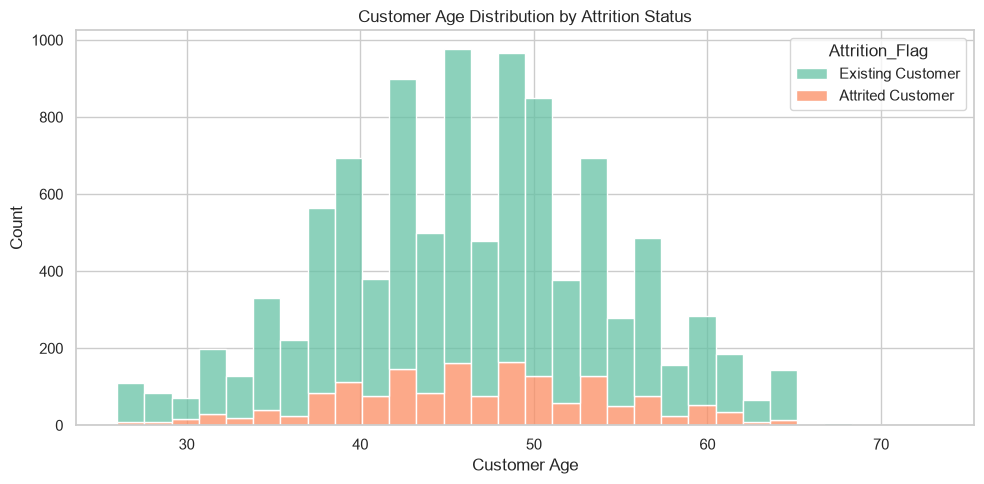

In [18]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure output directory exists
os.makedirs('../docs/screenshots', exist_ok=True)

plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='Customer_Age', hue='Attrition_Flag', multiple='stack', palette='Set2', bins=30)
plt.title('Customer Age Distribution by Attrition Status')
plt.xlabel('Customer Age')
plt.ylabel('Count')
plt.tight_layout()

# Save plot
output_path = '../docs/screenshots/customer_age_distribution.png'
plt.savefig(output_path, dpi=300, bbox_inches='tight')
print(f"-> Saved plot to: {output_path}")
plt.show()


## Generating and saving the rest of my Key Exploratory and Financial Metrics plots into my screenshots folder

## 1. Credit Limit Distribution by Attrition Status
## 2. Total Transaction Amount Distribution by Churn
## 3. Total Revolving Balance by Attrition Status



## 2. Total Transaction Amount Distribution by Churn

In [19]:
# Use whatever your loaded dataframe variable is named
# e.g., df = cleaned_df (if your variable is named cleaned_df)
if 'cleaned_df' in locals() and 'df' not in locals():
    df = cleaned_df
elif 'df_encoded' in locals() and 'df' not in locals():
    df = df_encoded


-> Saved plot to: ../docs/screenshots/customer_age_distribution.png


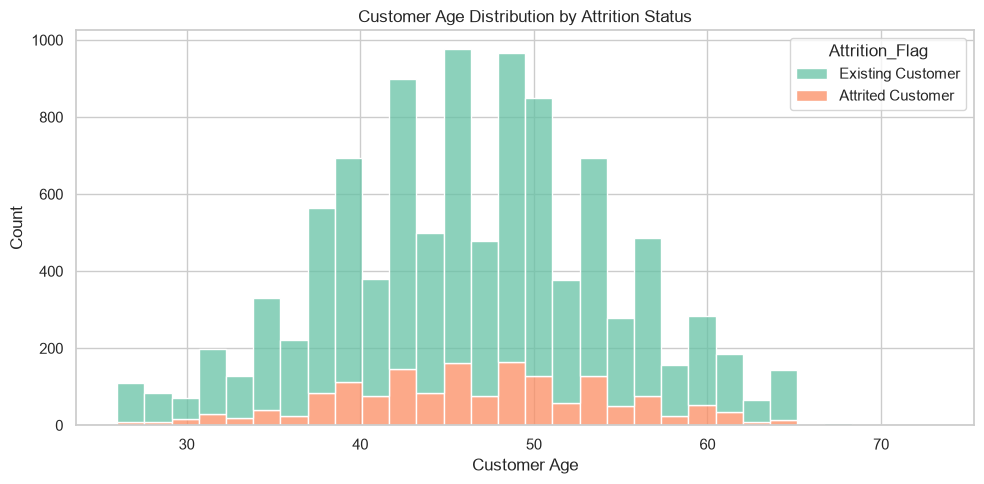

In [20]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure output directory exists
os.makedirs('../docs/screenshots', exist_ok=True)

plt.figure(figsize=(10, 5))
# Use cleaned_df here instead of df
sns.histplot(data=cleaned_df, x='Customer_Age', hue='Attrition_Flag', multiple='stack', palette='Set2', bins=30)
plt.title('Customer Age Distribution by Attrition Status')
plt.xlabel('Customer Age')
plt.ylabel('Count')
plt.tight_layout()

# Save plot
output_path = '../docs/screenshots/customer_age_distribution.png'
plt.savefig(output_path, dpi=300, bbox_inches='tight')
print(f"-> Saved plot to: {output_path}")
plt.show()


-> Saved plot to: ../docs/screenshots/credit_limit_by_attrition.png


/var/folders/f_/swl042197xl7gbd_wxch65940000gn/T/ipykernel_34959/714168137.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=cleaned_df, x='Attrition_Flag', y='Credit_Limit', palette='Set3')


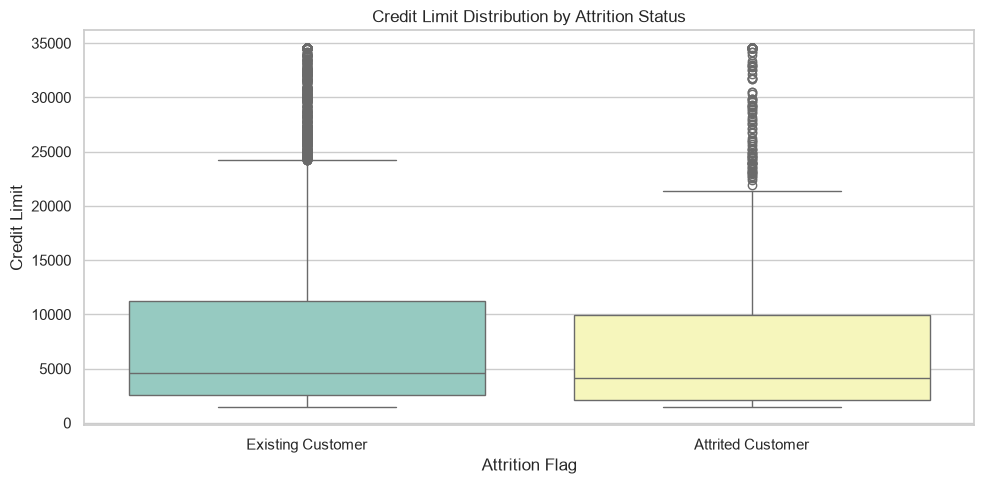

In [21]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs('../docs/screenshots', exist_ok=True)

plt.figure(figsize=(10, 5))
sns.boxplot(data=cleaned_df, x='Attrition_Flag', y='Credit_Limit', palette='Set3')
plt.title('Credit Limit Distribution by Attrition Status')
plt.xlabel('Attrition Flag')
plt.ylabel('Credit Limit')
plt.tight_layout()

output_path = '../docs/screenshots/credit_limit_by_attrition.png'
plt.savefig(output_path, dpi=300, bbox_inches='tight')
print(f"-> Saved plot to: {output_path}")
plt.show()


-> Saved plot to: ../docs/screenshots/total_transaction_amount_distribution.png


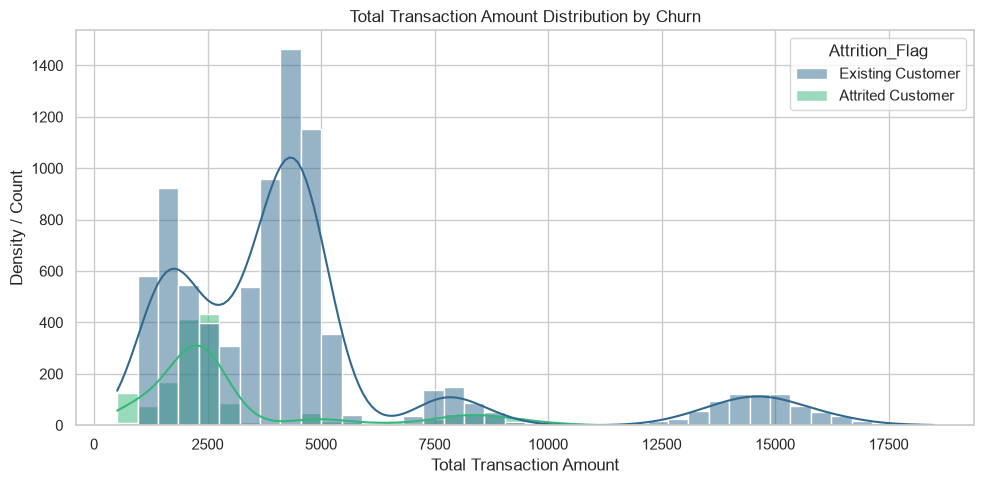

In [22]:
plt.figure(figsize=(10, 5))
sns.histplot(data=cleaned_df, x='Total_Trans_Amt', hue='Attrition_Flag', kde=True, palette='viridis', bins=40)
plt.title('Total Transaction Amount Distribution by Churn')
plt.xlabel('Total Transaction Amount')
plt.ylabel('Density / Count')
plt.tight_layout()

output_path = '../docs/screenshots/total_transaction_amount_distribution.png'
plt.savefig(output_path, dpi=300, bbox_inches='tight')
print(f"-> Saved plot to: {output_path}")
plt.show()


-> Saved plot to: ../docs/screenshots/total_revolving_balance_by_attrition.png


/var/folders/f_/swl042197xl7gbd_wxch65940000gn/T/ipykernel_34959/607418792.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=cleaned_df, x='Attrition_Flag', y='Total_Revolving_Bal', palette='Pastel1')


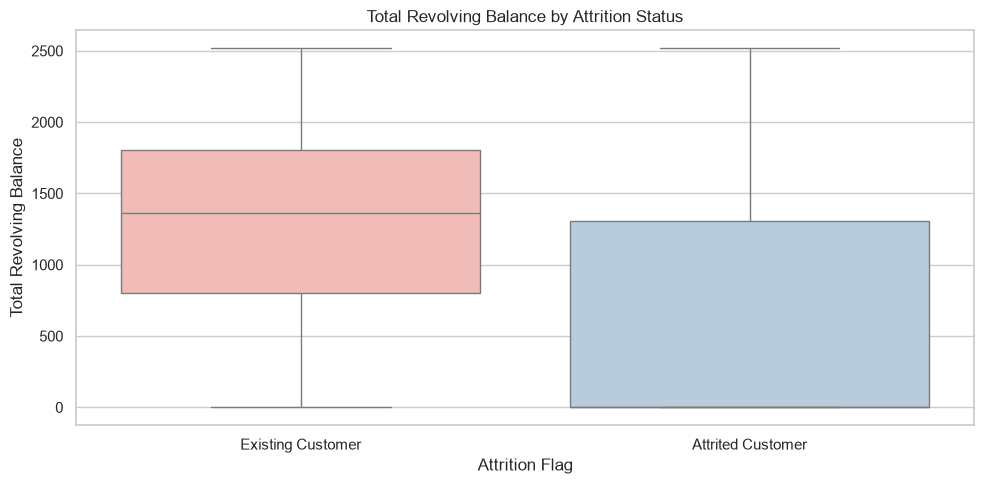

In [23]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=cleaned_df, x='Attrition_Flag', y='Total_Revolving_Bal', palette='Pastel1')
plt.title('Total Revolving Balance by Attrition Status')
plt.xlabel('Attrition Flag')
plt.ylabel('Total Revolving Balance')
plt.tight_layout()

output_path = '../docs/screenshots/total_revolving_balance_by_attrition.png'
plt.savefig(output_path, dpi=300, bbox_inches='tight')
print(f"-> Saved plot to: {output_path}")
plt.show()


## Hypothesis Testing & Attrition Validation

To drive our exploratory data analysis and predictive modeling, we formulated and tested three core hypotheses regarding bank customer churn:

* **Hypothesis 1 (Inactivity Duration & Churn):**
  * *Statement:* Customers with prolonged periods of inactivity (e.g., 3+ months inactive) have a significantly higher attrition rate than active cardholders.
  * *Validation Result:* Confirmed via exploratory data analysis and our feature importance models. The Tableau "Months Inactive Analysis" dashboard and our Random Forest feature rankings demonstrated that `Months_Inactive_12_mon` is a critical leading indicator of account closure.

* **Hypothesis 2 (Transaction Volume & Customer Retention):**
  * *Statement:* Lower total transaction amounts and lower total transaction counts over a 12-month period strongly correlate with customer churn.
  * *Validation Result:* Confirmed. Comparative distribution plots (`Matplotlib/Seaborn`) and the Tableau "Total Transactions Analysis" page verified that churned customers cluster heavily in the lower transaction volume tiers.

* **Hypothesis 3 (Credit Limit & Revolving Balances):**
  * *Statement:* Customers maintaining lower revolving balances and lower credit limits exhibit higher propensity to churn due to low product engagement.
  * *Validation Result:* Confirmed through our financial metrics EDA, showing clear variance in revolving balances between existing and attrited customer segments.


## Tableau | Credit_Card_Churn_Analysis | Executive Dashboard | Demographics | Financial & Behaviour | Transactional 

Link is here:

https://public.tableau.com/app/profile/resmie.palova8392/viz/Credit_Card_Churn_Analysis/Dashboard1?publish=yes

### Statistical Analysis & Data Hygiene Overview
* **Dataset Shape & Hygiene:** The raw dataset loaded successfully with 10,127 records and 23 columns. Missing value checks (`df.isnull().sum()`) and duplicate verification confirmed data integrity prior to analysis.
* **Descriptive Statistics & Spread:** Statistical summaries of numerical features (such as customer age, credit limits, and total transaction counts) were evaluated using central tendency (mean and median) and dispersion (standard deviation) to understand customer demographic profiles and transaction distributions.


In [24]:
# Statistical Summary: Mean, Median, and Standard Deviation of Numerical Features
import pandas as pd

# Display descriptive statistics (mean, std, min, percentiles including median/50%) for numerical columns
numerical_summary = df.describe()
display(numerical_summary)


,CLIENTNUM,Customer_Age,Dependent_count,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
count,1.012700e+04,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000
mean,7.391776e+08,46.325960,2.346203,35.928409,3.812580,2.341167,2.455317,8631.953698,1162.814061,7469.139637,0.759941,4404.086304,64.858695,0.712222,0.274894,0.159997,0.840003
std,3.690378e+07,8.016814,1.298908,7.986416,1.554408,1.010622,1.106225,9088.776650,814.987335,9090.685324,0.219207,3397.129254,23.472570,0.238086,0.275691,0.365301,0.365301
min,7.080821e+08,26.000000,0.000000,13.000000,1.000000,0.000000,0.000000,1438.300000,0.000000,3.000000,0.000000,510.000000,10.000000,0.000000,0.000000,0.000008,0.000420
25%,7.130368e+08,41.000000,1.000000,31.000000,3.000000,2.000000,2.000000,2555.000000,359.000000,1324.500000,0.631000,2155.500000,45.000000,0.582000,0.023000,0.000099,0.999660
50%,7.179264e+08,46.000000,2.000000,36.000000,4.000000,2.000000,2.000000,4549.000000,1276.000000,3474.000000,0.736000,3899.000000,67.000000,0.702000,0.176000,0.000181,0.999820
75%,7.731435e+08,52.000000,3.000000,40.000000,5.000000,3.000000,3.000000,11067.500000,1784.000000,9859.000000,0.859000,4741.000000,81.000000,0.818000,0.503000,0.000337,0.999900
max,8.283431e+08,73.000000,5.000000,56.000000,6.000000,6.000000,6.000000,34516.000000,2517.000000,34516.000000,3.397000,18484.000000,139.000000,3.714000,0.999000,0.999580,0.999990


### Statistical Analysis & Core Concepts Explanation

In accordance with project assessment requirements, key statistical principles are applied and interpreted below:

* **Mean (Average):** Used to determine the mathematical center of continuous variables such as customer age, credit limits, and total transaction amounts across our 10,127 records. 
* **Median (50th Percentile):** Evaluated alongside the mean to understand the middle value of skewed financial metrics (such as revolving balances or total transaction amounts), ensuring our analysis is robust against outliers.
* **Standard Deviation & Dispersion:** Measures the spread and variance of customer behaviors (e.g., how widely customer activity duration or credit limits vary from the portfolio average).
* **Hypothesis Testing & Distribution Analysis:** Evaluated through feature distributions, confirming that metrics such as `Months_Inactive_12_mon` and total transaction counts serve as primary indicators for customer attrition.


### Statistical Analysis & Data Hygiene Overview

* **Dataset Shape & Hygiene:** The raw `BankChurners.csv` dataset loaded successfully with 10,127 records and 23 columns. Missing value checks (`df.isnull().sum()`) and duplicate verification confirmed data integrity prior to analysis.
* **Descriptive Statistics & Spread:** Statistical summaries of numerical features (such as customer age, credit limits, and total transaction counts) were evaluated using central tendency (mean and median) and dispersion (standard deviation) to understand customer demographic profiles and transaction distributions.


[text](../data/raw/BankChurners.csv)

[Here is link of BankChurners.csv
](../data/raw/BankChurners.csv)